In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

In [ ]:
%pip install -q tiktoken pandas scikit-learn matplotlib gradio

In [1]:
import torch
import tiktoken
import pandas as pd
import sklearn
import matplotlib
import gradio as gr

print("All libraries imported successfully!")
print("GPU available:", torch.cuda.is_available())

All libraries imported successfully!
GPU available: True


In [5]:
import os
import urllib.request

os.makedirs("data", exist_ok=True)

url = (
    "https://huggingface.co/datasets/"
    "alexcadillon/SemEval2014Task4/resolve/main/"
    "SemEval%2714-ABSA-TrainData_v2%20%26%20"
    "AnnotationGuidelines/Laptop_Train_v2.xml"
)

urllib.request.urlretrieve(
    url,
    "data/Laptop_Train_v2.xml"
)

print("Laptop dataset downloaded successfully!")
print("File size:", os.path.getsize("data/Laptop_Train_v2.xml"), "bytes")

Laptop dataset downloaded successfully!
File size: 687312 bytes


In [6]:
import xml.etree.ElementTree as ET
import pandas as pd

# Load the downloaded XML file
tree = ET.parse("data/Laptop_Train_v2.xml")
root = tree.getroot()

data = []

# Extract each review and its aspects
for sentence in root.findall("sentence"):

    sentence_id = sentence.get("id")
    review = sentence.findtext("text")

    aspect_terms = sentence.find("aspectTerms")

    if aspect_terms is not None:
        for aspect in aspect_terms.findall("aspectTerm"):

            aspect_name = aspect.get("term")
            polarity = aspect.get("polarity")

            # Our project uses exactly three classes
            if polarity in ["positive", "negative", "neutral"]:

                data.append({
                    "sentence_id": sentence_id,
                    "review": review,
                    "aspect": aspect_name,
                    "polarity": polarity
                })

# Convert extracted data into a DataFrame
df = pd.DataFrame(data)

print("Total aspect-level samples:", len(df))
print("\nFirst 5 samples:")
print(df.head())

print("\nSentiment distribution:")
print(df["polarity"].value_counts())

Total aspect-level samples: 2313

First 5 samples:
  sentence_id                                             review  \
0        2339  I charge it at night and skip taking the cord ...   
1        2339  I charge it at night and skip taking the cord ...   
2        1316  The tech guy then said the service center does...   
3        1316  The tech guy then said the service center does...   
4        1316  The tech guy then said the service center does...   

           aspect  polarity  
0            cord   neutral  
1    battery life  positive  
2  service center  negative  
3    "sales" team  negative  
4        tech guy   neutral  

Sentiment distribution:
polarity
positive    987
negative    866
neutral     460
Name: count, dtype: int64


In [7]:
# Convert sentiment labels into numbers
label_to_id = {
    "negative": 0,
    "neutral": 1,
    "positive": 2
}

id_to_label = {
    0: "negative",
    1: "neutral",
    2: "positive"
}

# Create the input format required by the project
def format_input(review, aspect):
    return f"Review: {review}\nAspect: {aspect}"

# Prepare model input and numerical labels
df["input_text"] = df.apply(
    lambda row: format_input(
        row["review"],
        row["aspect"]
    ),
    axis=1
)

df["label"] = df["polarity"].map(label_to_id)

# Display one example
print("MODEL INPUT:")
print(df.iloc[0]["input_text"])

print("\nNUMERICAL LABEL:")
print(df.iloc[0]["label"])

print("\nDATASET SHAPE:")
print(df.shape)

MODEL INPUT:
Review: I charge it at night and skip taking the cord with me because of the good battery life.
Aspect: cord

NUMERICAL LABEL:
1

DATASET SHAPE:
(2313, 6)


In [8]:
from sklearn.model_selection import GroupShuffleSplit

# Create a group-based splitter
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.15,
    random_state=42
)

# Split using sentence_id to prevent data leakage
train_idx, val_idx = next(
    splitter.split(
        df,
        groups=df["sentence_id"]
    )
)

# Create training and validation DataFrames
train_df = df.iloc[train_idx].reset_index(drop=True)
val_df = df.iloc[val_idx].reset_index(drop=True)

# Display results
print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))

print("\nTraining sentiment distribution:")
print(train_df["polarity"].value_counts())

print("\nValidation sentiment distribution:")
print(val_df["polarity"].value_counts())

# Verify that reviews don't overlap
overlap = set(train_df["sentence_id"]) & set(val_df["sentence_id"])

print("\nOverlapping sentence IDs:", len(overlap))

Training samples: 1995
Validation samples: 318

Training sentiment distribution:
polarity
positive    840
negative    736
neutral     419
Name: count, dtype: int64

Validation sentiment distribution:
polarity
positive    147
negative    130
neutral      41
Name: count, dtype: int64

Overlapping sentence IDs: 0


In [9]:
import tiktoken
import numpy as np

# Load GPT-2 tokenizer
tokenizer = tiktoken.get_encoding("gpt2")

# Select the first training sample
sample_text = train_df.iloc[0]["input_text"]

# Convert text into token IDs
token_ids = tokenizer.encode(sample_text)

# Convert token IDs back into text
decoded_text = tokenizer.decode(token_ids)

print("ORIGINAL TEXT:")
print(sample_text)

print("\nTOKEN IDS:")
print(token_ids)

print("\nNUMBER OF TOKENS:")
print(len(token_ids))

print("\nDECODED TEXT:")
print(decoded_text)

# Examine lengths across all training samples
token_lengths = [
    len(tokenizer.encode(text))
    for text in train_df["input_text"]
]

print("\nMAXIMUM TOKEN LENGTH:", max(token_lengths))
print("AVERAGE TOKEN LENGTH:", round(np.mean(token_lengths), 2))
print("95TH PERCENTILE:", np.percentile(token_lengths, 95))

ORIGINAL TEXT:
Review: I charge it at night and skip taking the cord with me because of the good battery life.
Aspect: cord

TOKEN IDS:
[14832, 25, 314, 3877, 340, 379, 1755, 290, 14267, 2263, 262, 15050, 351, 502, 780, 286, 262, 922, 6555, 1204, 13, 198, 1722, 806, 25, 15050]

NUMBER OF TOKENS:
26

DECODED TEXT:
Review: I charge it at night and skip taking the cord with me because of the good battery life.
Aspect: cord

MAXIMUM TOKEN LENGTH: 97
AVERAGE TOKEN LENGTH: 30.86
95TH PERCENTILE: 54.0


In [10]:
import torch
from torch.utils.data import Dataset, DataLoader

MAX_LENGTH = 128
PAD_TOKEN_ID = 50256

class LaptopDataset(Dataset):

    def __init__(self, dataframe, tokenizer):

        self.samples = []

        for _, row in dataframe.iterrows():

            # Get formatted review and aspect
            text = row["input_text"]

            # Convert text into token IDs
            token_ids = tokenizer.encode(text)

            # Truncate if longer than 128 tokens
            token_ids = token_ids[:MAX_LENGTH]

            # Position of the last real token
            last_position = len(token_ids) - 1

            # Add padding tokens
            padding_needed = MAX_LENGTH - len(token_ids)

            token_ids += [PAD_TOKEN_ID] * padding_needed

            # Get numerical sentiment label
            label = int(row["label"])

            self.samples.append((
                torch.tensor(token_ids, dtype=torch.long),
                torch.tensor(last_position, dtype=torch.long),
                torch.tensor(label, dtype=torch.long)
            ))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        return self.samples[index]


# Create training and validation datasets
train_dataset = LaptopDataset(train_df, tokenizer)
val_dataset = LaptopDataset(val_df, tokenizer)

# Test the dataset
input_ids, last_position, label = train_dataset[0]

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))

print("\nToken tensor shape:", input_ids.shape)
print("Last real token position:", last_position.item())
print("Sentiment label:", label.item())
print("Padding tokens:", (input_ids == PAD_TOKEN_ID).sum().item())

Training samples: 1995
Validation samples: 318

Token tensor shape: torch.Size([128])
Last real token position: 25
Sentiment label: 1
Padding tokens: 102


In [11]:
from torch.utils.data import DataLoader

BATCH_SIZE = 8

# Training DataLoader
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=False
)

# Validation DataLoader
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    drop_last=False
)

# Get one batch to test
input_batch, position_batch, label_batch = next(
    iter(train_loader)
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

print("\nInput batch shape:", input_batch.shape)
print("Position batch shape:", position_batch.shape)
print("Label batch shape:", label_batch.shape)

print("\nLabels in first batch:", label_batch)

Training batches: 250
Validation batches: 40

Input batch shape: torch.Size([8, 128])
Position batch shape: torch.Size([8])
Label batch shape: torch.Size([8])

Labels in first batch: tensor([2, 0, 1, 0, 0, 0, 1, 0])


In [12]:
import urllib.request
import os

MODEL_CODE_URL = (
    "https://raw.githubusercontent.com/rasbt/"
    "LLMs-from-scratch/main/ch06/01_main-chapter-code/"
    "previous_chapters.py"
)

urllib.request.urlretrieve(
    MODEL_CODE_URL,
    "previous_chapters.py"
)

print("GPT-2 course model code downloaded!")

print("File size:",
      os.path.getsize("previous_chapters.py"),
      "bytes")

GPT-2 course model code downloaded!
File size: 12067 bytes


In [13]:
import torch
from previous_chapters import GPTModel

# GPT-2 Small configuration
GPT_CONFIG_124M = {
    "vocab_size": 50257,
    "context_length": 1024,
    "emb_dim": 768,
    "n_heads": 12,
    "n_layers": 12,
    "drop_rate": 0.0,
    "qkv_bias": True
}

# Initialize GPT-2 architecture
model = GPTModel(GPT_CONFIG_124M)

# Calculate number of parameters
total_params = sum(
    p.numel() for p in model.parameters()
)

print("GPT-2 model created successfully!")
print(f"Total parameters: {total_params:,}")
print("Transformer blocks:", len(model.trf_blocks))
print("Embedding dimension:", GPT_CONFIG_124M["emb_dim"])

GPT-2 model created successfully!
Total parameters: 163,037,184
Transformer blocks: 12
Embedding dimension: 768


In [14]:
import urllib.request
import os
import importlib.util

# Official course code
url = (
    "https://raw.githubusercontent.com/rasbt/"
    "LLMs-from-scratch/main/ch06/"
    "01_main-chapter-code/gpt_download.py"
)

# Download the weight-loading module
urllib.request.urlretrieve(
    url,
    "gpt_download.py"
)

print("GPT-2 download module downloaded successfully!")

print(
    "File size:",
    os.path.getsize("gpt_download.py"),
    "bytes"
)

# Check whether TensorFlow is available
print(
    "TensorFlow installed:",
    importlib.util.find_spec("tensorflow") is not None
)

GPT-2 download module downloaded successfully!
File size: 6025 bytes
TensorFlow installed: True


In [15]:
from gpt_download import download_and_load_gpt2

# Download GPT-2 Small pretrained weights
settings, params = download_and_load_gpt2(
    model_size="124M",
    models_dir="gpt2"
)

print("\nGPT-2 pretrained weights downloaded!")

print("\nModel settings:")
print(settings)

print("\nNumber of transformer blocks:",
      len(params["blocks"]))

checkpoint: 100%|██████████| 77.0/77.0 [00:00<00:00, 250kiB/s]
encoder.json: 100%|██████████| 1.04M/1.04M [00:00<00:00, 4.66MiB/s]
hparams.json: 100%|██████████| 90.0/90.0 [00:00<00:00, 184kiB/s]
model.ckpt.data-00000-of-00001: 100%|██████████| 498M/498M [00:33<00:00, 15.1MiB/s] 
model.ckpt.index: 100%|██████████| 5.21k/5.21k [00:00<00:00, 9.18MiB/s]
model.ckpt.meta: 100%|██████████| 471k/471k [00:00<00:00, 3.99MiB/s]
vocab.bpe: 100%|██████████| 456k/456k [00:00<00:00, 1.47MiB/s]



GPT-2 pretrained weights downloaded!

Model settings:
{'n_vocab': 50257, 'n_ctx': 1024, 'n_embd': 768, 'n_head': 12, 'n_layer': 12}

Number of transformer blocks: 12


In [16]:
from previous_chapters import load_weights_into_gpt

# Load pretrained GPT-2 weights into our model
load_weights_into_gpt(model, params)

print("Pretrained GPT-2 weights loaded successfully!")

# Verify model architecture
print("Transformer blocks:", len(model.trf_blocks))

print("Embedding dimension:", GPT_CONFIG_124M["emb_dim"])

# Verify output head shape
print("Output head shape:", model.out_head.weight.shape)

Pretrained GPT-2 weights loaded successfully!
Transformer blocks: 12
Embedding dimension: 768
Output head shape: torch.Size([50257, 768])


In [17]:
import torch
from torch import nn

# Replace GPT-2's vocabulary output head
# with a 3-class sentiment classification head

torch.manual_seed(42)

model.out_head = nn.Linear(
    in_features=768,
    out_features=3
)

# Display the new classification head
print("New classification head:")
print(model.out_head)

# Verify its weight dimensions
print("\nClassification head weight shape:")
print(model.out_head.weight.shape)

# Display parameter count
total_params = sum(
    p.numel() for p in model.parameters()
)

print("\nTotal model parameters:")
print(f"{total_params:,}")

New classification head:
Linear(in_features=768, out_features=3, bias=True)

Classification head weight shape:
torch.Size([3, 768])

Total model parameters:
124,442,115


In [18]:
# Step 13: Freeze and unfreeze selected layers

# Freeze all model parameters
for param in model.parameters():
    param.requires_grad = False

# Unfreeze the last transformer block
for param in model.trf_blocks[-1].parameters():
    param.requires_grad = True

# Unfreeze the final normalization layer
for param in model.final_norm.parameters():
    param.requires_grad = True

# Unfreeze the classification head
for param in model.out_head.parameters():
    param.requires_grad = True

# Count parameters
total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("Total parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")

print(
    "Frozen parameters:",
    f"{total_params - trainable_params:,}"
)

print(
    "Trainable percentage:",
    round(trainable_params / total_params * 100, 2),
    "%"
)

# Move model to GPU
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = model.to(device)

print("\nModel running on:", device)

Total parameters: 124,442,115
Trainable parameters: 7,091,715
Frozen parameters: 117,350,400
Trainable percentage: 5.7 %

Model running on: cuda


In [19]:
import torch
from sklearn.metrics import accuracy_score, f1_score

def evaluate_model(model, data_loader):
    model.eval()

    all_predictions = []
    all_labels = []

    with torch.no_grad():

        for input_ids, last_positions, labels in data_loader:

            # Move data to GPU
            input_ids = input_ids.to(device)
            last_positions = last_positions.to(device)

            # GPT-2 output: [batch_size, sequence_length, 3]
            logits = model(input_ids)

            # Select the last real token for each review
            batch_indices = torch.arange(
                input_ids.size(0),
                device=device
            )

            classification_logits = logits[
                batch_indices,
                last_positions
            ]

            # Choose the class with the highest score
            predictions = torch.argmax(
                classification_logits,
                dim=-1
            )

            all_predictions.extend(
                predictions.cpu().tolist()
            )

            all_labels.extend(
                labels.tolist()
            )

    accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        labels=[0, 1, 2],
        average="macro",
        zero_division=0
    )

    return accuracy, macro_f1


# Measure performance before fine-tuning
baseline_accuracy, baseline_f1 = evaluate_model(
    model,
    val_loader
)

print("BASELINE RESULTS (BEFORE FINE-TUNING)")
print("-------------------------------------")
print(f"Accuracy: {baseline_accuracy:.4f}")
print(f"Macro-F1: {baseline_f1:.4f}")

BASELINE RESULTS (BEFORE FINE-TUNING)
-------------------------------------
Accuracy: 0.1289
Macro-F1: 0.0761


In [20]:
import torch
from torch import nn
from tqdm.auto import tqdm

# Configure optimizer
optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=5e-5,
    weight_decay=0.01
)

# Loss function for 3-class classification
loss_fn = nn.CrossEntropyLoss()

EPOCHS = 3

train_losses = []
val_accuracies = []
val_f1_scores = []

for epoch in range(EPOCHS):

    model.train()
    total_loss = 0.0

    progress_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch + 1}/{EPOCHS}"
    )

    for input_ids, last_positions, labels in progress_bar:

        input_ids = input_ids.to(device)
        last_positions = last_positions.to(device)
        labels = labels.to(device)

        # Reset gradients
        optimizer.zero_grad()

        # Forward pass
        logits = model(input_ids)

        batch_indices = torch.arange(
            input_ids.size(0),
            device=device
        )

        # Select scores from last real token
        classification_logits = logits[
            batch_indices,
            last_positions
        ]

        # Calculate loss
        loss = loss_fn(classification_logits, labels)

        # Backpropagation
        loss.backward()

        # Limit gradient magnitude
        torch.nn.utils.clip_grad_norm_(
            filter(
                lambda p: p.requires_grad,
                model.parameters()
            ),
            max_norm=1.0
        )

        # Update trainable parameters
        optimizer.step()

        total_loss += loss.item()

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    avg_train_loss = total_loss / len(train_loader)

    # Evaluate after each epoch
    val_accuracy, val_f1 = evaluate_model(
        model,
        val_loader
    )

    train_losses.append(avg_train_loss)
    val_accuracies.append(val_accuracy)
    val_f1_scores.append(val_f1)

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")
    print(f"Training Loss: {avg_train_loss:.4f}")
    print(f"Validation Accuracy: {val_accuracy:.4f}")
    print(f"Validation Macro-F1: {val_f1:.4f}")
    print("-" * 40)

    # Save checkpoint with best validation Macro-F1
    if val_f1 == max(val_f1_scores):
        torch.save(
            model.state_dict(),
            "best_laptop_gpt2.pth"
        )
        print("Best model checkpoint saved!")

Epoch 1/3:   0%|          | 0/250 [00:00<?, ?it/s]


Epoch 1/3
Training Loss: 1.5692
Validation Accuracy: 0.7390
Validation Macro-F1: 0.5797
----------------------------------------
Best model checkpoint saved!


Epoch 2/3:   0%|          | 0/250 [00:00<?, ?it/s]


Epoch 2/3
Training Loss: 0.7178
Validation Accuracy: 0.7704
Validation Macro-F1: 0.6803
----------------------------------------
Best model checkpoint saved!


Epoch 3/3:   0%|          | 0/250 [00:00<?, ?it/s]


Epoch 3/3
Training Loss: 0.6018
Validation Accuracy: 0.7956
Validation Macro-F1: 0.7170
----------------------------------------
Best model checkpoint saved!


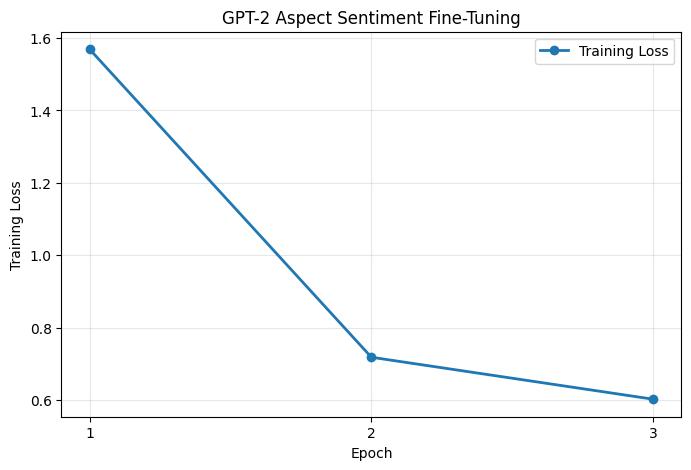

Training loss curve saved!
Loss values: [1.5691687835454942, 0.7177739459872245, 0.6017650652825832]


In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(train_losses) + 1),
    train_losses,
    marker="o",
    linewidth=2,
    label="Training Loss"
)

plt.title("GPT-2 Aspect Sentiment Fine-Tuning")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")

plt.xticks(range(1, len(train_losses) + 1))
plt.grid(True, alpha=0.3)
plt.legend()

plt.savefig(
    "training_loss_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Training loss curve saved!")
print("Loss values:", train_losses)

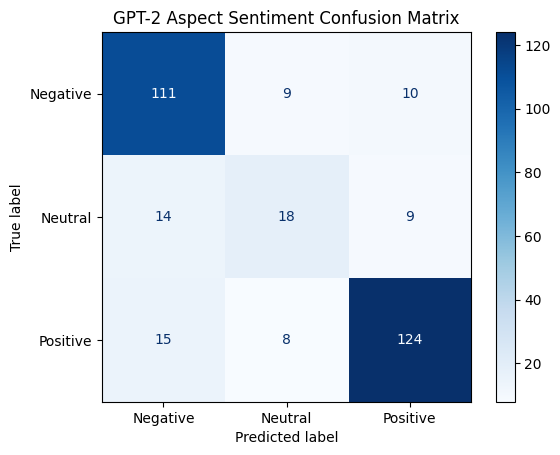


CLASSIFICATION REPORT:
              precision    recall  f1-score   support

    Negative       0.79      0.85      0.82       130
     Neutral       0.51      0.44      0.47        41
    Positive       0.87      0.84      0.86       147

    accuracy                           0.80       318
   macro avg       0.72      0.71      0.72       318
weighted avg       0.79      0.80      0.79       318



In [22]:
import torch
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

# Load the best saved model
model.load_state_dict(
    torch.load(
        "best_laptop_gpt2.pth",
        map_location=device,
        weights_only=True
    )
)

model.eval()

actual_labels = []
predicted_labels = []

with torch.no_grad():

    for input_ids, last_positions, labels in val_loader:

        input_ids = input_ids.to(device)
        last_positions = last_positions.to(device)

        # Get model predictions
        logits = model(input_ids)

        batch_indices = torch.arange(
            input_ids.size(0),
            device=device
        )

        classification_logits = logits[
            batch_indices,
            last_positions
        ]

        predictions = torch.argmax(
            classification_logits,
            dim=-1
        )

        actual_labels.extend(labels.tolist())
        predicted_labels.extend(
            predictions.cpu().tolist()
        )

# Generate confusion matrix
cm = confusion_matrix(
    actual_labels,
    predicted_labels,
    labels=[0, 1, 2]
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Neutral", "Positive"]
)

display.plot(cmap="Blues", values_format="d")

plt.title("GPT-2 Aspect Sentiment Confusion Matrix")
plt.savefig(
    "confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nCLASSIFICATION REPORT:")
print(
    classification_report(
        actual_labels,
        predicted_labels,
        labels=[0, 1, 2],
        target_names=["Negative", "Neutral", "Positive"],
        zero_division=0
    )
)

In [23]:
import urllib.request
import xml.etree.ElementTree as ET
import pandas as pd
import os

# Download gold-labeled laptop test dataset
test_url = (
    "https://huggingface.co/datasets/"
    "alexcadillon/SemEval2014Task4/resolve/main/"
    "ABSA_Gold_TestData/Laptops_Test_Gold.xml"
)

test_path = "data/Laptops_Test_Gold.xml"

urllib.request.urlretrieve(test_url, test_path)

print("Test dataset downloaded successfully!")
print("File size:", os.path.getsize(test_path), "bytes")

# Parse XML
tree = ET.parse(test_path)
root = tree.getroot()

test_data = []

for sentence in root.findall("sentence"):

    sentence_id = sentence.get("id")
    review = sentence.findtext("text")

    aspect_terms = sentence.find("aspectTerms")

    if aspect_terms is not None:
        for aspect in aspect_terms.findall("aspectTerm"):

            polarity = aspect.get("polarity")

            if polarity in ["positive", "negative", "neutral"]:

                test_data.append({
                    "sentence_id": sentence_id,
                    "review": review,
                    "aspect": aspect.get("term"),
                    "polarity": polarity
                })

test_df = pd.DataFrame(test_data)

print("\nTotal test samples:", len(test_df))
print("\nTest sentiment distribution:")
print(test_df["polarity"].value_counts())

print("\nFirst 5 test samples:")
print(test_df.head())

Test dataset downloaded successfully!
File size: 178754 bytes

Total test samples: 638

Test sentiment distribution:
polarity
positive    341
neutral     169
negative    128
Name: count, dtype: int64

First 5 test samples:
  sentence_id                                             review  \
0       892:1  Boot time is super fast, around anywhere from ...   
1      1144:1  tech support would not fix the problem unless ...   
2       359:1                                   Set up was easy.   
3       562:1  Did not enjoy the new Windows 8 and touchscree...   
4       562:1  Did not enjoy the new Windows 8 and touchscree...   

                  aspect  polarity  
0              Boot time  positive  
1           tech support  negative  
2                 Set up  positive  
3              Windows 8  negative  
4  touchscreen functions  negative  


In [24]:
# Step 19: Prepare and evaluate the test dataset

from torch.utils.data import DataLoader
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Convert test samples to the required input format
test_df["input_text"] = test_df.apply(
    lambda row: format_input(
        row["review"],
        row["aspect"]
    ),
    axis=1
)

# Convert sentiment labels to numbers
test_df["label"] = test_df["polarity"].map(label_to_id)

# Create test Dataset and DataLoader
test_dataset = LaptopDataset(test_df, tokenizer)

test_loader = DataLoader(
    test_dataset,
    batch_size=8,
    shuffle=False
)

# Load the best fine-tuned checkpoint
model.load_state_dict(
    torch.load(
        "best_laptop_gpt2.pth",
        map_location=device,
        weights_only=True
    )
)

model.eval()

# Calculate test metrics
test_accuracy, test_f1 = evaluate_model(
    model,
    test_loader
)

print("FINAL TEST RESULTS")
print("----------------------------")
print(f"Test samples: {len(test_dataset)}")
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test macro-F1: {test_f1:.4f}")

FINAL TEST RESULTS
----------------------------
Test samples: 638
Test accuracy: 0.7241
Test macro-F1: 0.6675


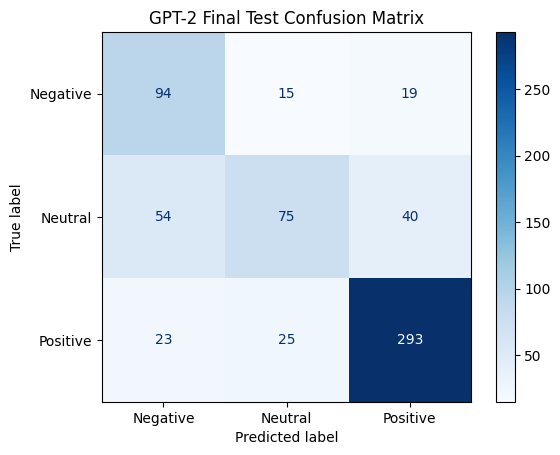


FINAL TEST CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Negative       0.55      0.73      0.63       128
     Neutral       0.65      0.44      0.53       169
    Positive       0.83      0.86      0.85       341

    accuracy                           0.72       638
   macro avg       0.68      0.68      0.67       638
weighted avg       0.73      0.72      0.72       638



In [25]:
import torch
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

actual = []
predicted = []

model.eval()

with torch.no_grad():
    for input_ids, last_positions, labels in test_loader:

        input_ids = input_ids.to(device)
        last_positions = last_positions.to(device)

        logits = model(input_ids)

        batch_indices = torch.arange(
            input_ids.size(0),
            device=device
        )

        classification_logits = logits[
            batch_indices,
            last_positions
        ]

        predictions = torch.argmax(
            classification_logits,
            dim=-1
        )

        actual.extend(labels.tolist())
        predicted.extend(predictions.cpu().tolist())

# Generate confusion matrix
cm = confusion_matrix(
    actual,
    predicted,
    labels=[0, 1, 2]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Neutral", "Positive"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("GPT-2 Final Test Confusion Matrix")

plt.savefig(
    "final_test_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nFINAL TEST CLASSIFICATION REPORT")
print(
    classification_report(
        actual,
        predicted,
        labels=[0, 1, 2],
        target_names=["Negative", "Neutral", "Positive"],
        zero_division=0
    )
)

In [26]:
def aspect_sentiment(review, aspect):

    # Validate inputs
    if not review.strip() or not aspect.strip():
        return "Please enter both a review and an aspect."

    # Format input exactly as during training
    text = format_input(review, aspect)

    # Tokenize
    token_ids = tokenizer.encode(text)

    # Truncate
    token_ids = token_ids[:MAX_LENGTH]

    # Find last real token position
    last_position = len(token_ids) - 1

    # Pad to required length
    token_ids += [PAD_TOKEN_ID] * (
        MAX_LENGTH - len(token_ids)
    )

    # Convert to tensors
    input_tensor = torch.tensor(
        [token_ids],
        dtype=torch.long,
        device=device
    )

    position_tensor = torch.tensor(
        [last_position],
        dtype=torch.long,
        device=device
    )

    # Prediction
    model.eval()

    with torch.no_grad():

        logits = model(input_tensor)

        classification_logits = logits[
            0,
            position_tensor.item()
        ]

        predicted_class = torch.argmax(
            classification_logits
        ).item()

    # Convert class number to sentiment
    return id_to_label[predicted_class]


# Test using two aspects in the same review
review = (
    "The laptop screen is amazing and very clear, "
    "but the battery life is terrible."
)

print("Screen sentiment:",
      aspect_sentiment(review, "screen"))

print("Battery sentiment:",
      aspect_sentiment(review, "battery"))

Screen sentiment: positive
Battery sentiment: negative


In [27]:
import gradio as gr

# Create the application interface
demo = gr.Interface(
    fn=aspect_sentiment,

    inputs=[
        gr.Textbox(
            label="Laptop Review",
            placeholder="Enter your laptop review here...",
            lines=4
        ),

        gr.Textbox(
            label="Aspect",
            placeholder="Example: battery, screen, keyboard"
        )
    ],

    outputs=gr.Textbox(
        label="Predicted Sentiment"
    ),

    title="Laptop Aspect-Level Sentiment Analyzer",

    description=(
        "Analyze customer sentiment toward specific "
        "laptop aspects using a fine-tuned GPT-2 model."
    ),

    examples=[
        [
            "The screen is beautiful but the battery is terrible.",
            "screen"
        ],
        [
            "The screen is beautiful but the battery is terrible.",
            "battery"
        ],
        [
            "The keyboard is comfortable and responsive.",
            "keyboard"
        ]
    ]
)

# Launch application
demo.launch(share=False)

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


In [28]:
demo.launch(share=True, inline=False)

Rerunning server... use `close()` to stop if you need to change `launch()` parameters.
----
* Running on public URL: https://5e10ecc2d8a44d12b0.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [29]:
import torch
from torch import nn
from previous_chapters import GPTModel

# Create a fresh GPT-2 model instance
reloaded_model = GPTModel(GPT_CONFIG_124M)

# Add the same 3-class classification head
reloaded_model.out_head = nn.Linear(
    in_features=768,
    out_features=3
)

# Load saved fine-tuned weights
checkpoint = torch.load(
    "best_laptop_gpt2.pth",
    map_location="cpu",
    weights_only=True
)

reloaded_model.load_state_dict(checkpoint)

# Move the model to GPU
reloaded_model = reloaded_model.to(device)

# Switch to evaluation mode
reloaded_model.eval()

print("Model checkpoint reloaded successfully!")

# Verify one batch produces identical predictions
input_ids, last_positions, labels = next(iter(val_loader))

input_ids = input_ids.to(device)
last_positions = last_positions.to(device)

batch_indices = torch.arange(
    input_ids.size(0),
    device=device
)

with torch.no_grad():

    original_logits = model(input_ids)[
        batch_indices, last_positions
    ]

    reloaded_logits = reloaded_model(input_ids)[
        batch_indices, last_positions
    ]

    original_predictions = original_logits.argmax(dim=-1)
    reloaded_predictions = reloaded_logits.argmax(dim=-1)

print("Original predictions:",
      original_predictions.cpu().tolist())

print("Reloaded predictions:",
      reloaded_predictions.cpu().tolist())

print(
    "Predictions match:",
    torch.equal(original_predictions, reloaded_predictions)
)

print(
    "Logits match:",
    torch.allclose(original_logits, reloaded_logits)
)

Model checkpoint reloaded successfully!
Original predictions: [2, 2, 2, 0, 0, 0, 0, 0]
Reloaded predictions: [2, 2, 2, 0, 0, 0, 0, 0]
Predictions match: True
Logits match: False


In [30]:
# Put both models in evaluation mode
model.eval()
reloaded_model.eval()

# Calculate predictions again
with torch.no_grad():

    original_logits = model(input_ids)[
        batch_indices, last_positions
    ]

    reloaded_logits = reloaded_model(input_ids)[
        batch_indices, last_positions
    ]

# Measure the difference
max_difference = torch.max(
    torch.abs(original_logits - reloaded_logits)
).item()

print("Maximum logit difference:", max_difference)

print(
    "Logits match (tolerance 1e-4):",
    torch.allclose(
        original_logits,
        reloaded_logits,
        atol=1e-4,
        rtol=1e-4
    )
)

print(
    "Predictions match:",
    torch.equal(
        original_logits.argmax(dim=-1),
        reloaded_logits.argmax(dim=-1)
    )
)

Maximum logit difference: 5.0067901611328125e-06
Logits match (tolerance 1e-4): True
Predictions match: True


In [31]:
import pandas as pd
import os

os.makedirs("results", exist_ok=True)

# Save measured model performance
results_df = pd.DataFrame({
    "Evaluation Stage": [
        "Before Fine-Tuning (Validation)",
        "After Fine-Tuning (Validation)",
        "After Fine-Tuning (Test)"
    ],
    "Accuracy": [
        baseline_accuracy,
        0.7956,
        test_accuracy
    ],
    "Macro-F1": [
        baseline_f1,
        0.7170,
        test_f1
    ]
})

results_df.to_csv(
    "results/model_performance.csv",
    index=False
)

# Save training losses
loss_df = pd.DataFrame({
    "Epoch": range(1, len(train_losses) + 1),
    "Training Loss": train_losses,
    "Validation Accuracy": val_accuracies,
    "Validation Macro-F1": val_f1_scores
})

loss_df.to_csv(
    "results/training_history.csv",
    index=False
)

print("Final results saved successfully!")

print("\nMODEL PERFORMANCE:")
print(results_df)

print("\nTRAINING HISTORY:")
print(loss_df)

Final results saved successfully!

MODEL PERFORMANCE:
                  Evaluation Stage  Accuracy  Macro-F1
0  Before Fine-Tuning (Validation)  0.128931  0.076137
1   After Fine-Tuning (Validation)  0.795600  0.717000
2         After Fine-Tuning (Test)  0.724138  0.667510

TRAINING HISTORY:
   Epoch  Training Loss  Validation Accuracy  Validation Macro-F1
0      1       1.569169             0.738994             0.579732
1      2       0.717774             0.770440             0.680267
2      3       0.601765             0.795597             0.717026


In [32]:
# Step 25: Extract real classification errors

error_df = test_df.copy()

# Predictions from Step 20
error_df["predicted_label"] = predicted

# Convert numerical predictions to sentiment names
error_df["predicted_sentiment"] = (
    error_df["predicted_label"].map(id_to_label)
)

# Find incorrectly classified examples
errors = error_df[
    error_df["label"] != error_df["predicted_label"]
].copy()

# Save errors
errors.to_csv(
    "results/classification_errors.csv",
    index=False
)

print("Total test samples:", len(error_df))
print("Correct predictions:", len(error_df) - len(errors))
print("Incorrect predictions:", len(errors))

print("\nFIRST 5 CLASSIFICATION ERRORS:")
print(
    errors[
        [
            "review",
            "aspect",
            "polarity",
            "predicted_sentiment"
        ]
    ].head(5).to_string(index=False)
)

Total test samples: 638
Correct predictions: 462
Incorrect predictions: 176

FIRST 5 CLASSIFICATION ERRORS:
                                                                                                                                                                                                               review            aspect polarity predicted_sentiment
                                                                                                                                                           Did not enjoy the new Windows 8 and touchscreen functions.         Windows 8 negative            positive
Other than not being a fan of click pads (industry standard these days) and the lousy internal speakers, it's hard for me to find things about this notebook I don't like, especially considering the $350 price tag.         price tag positive            negative
                                                                                                             